# Multilayer Perceptron: UFC fight outcomes

## Question

Can pre-fight fighter records predict whether the Red or Blue corner wins? The reference study is McQuaide (2019), *Applying Machine Learning Algorithms to Predict UFC Fight Outcomes*. Its original dataset link is unavailable, so this project uses the public TidyTuesday UFC dataset and restricts it to 2010–2019.

## How this model works

A small neural network passes the fighter features through two hidden layers with 5 and 2 neurons. Nonlinear activation functions let it combine attributes in ways a linear model cannot. L-BFGS optimizes its weights, with log-loss as the objective.

### Why include it

The paper tests whether even a compact neural network can find nonlinear patterns in the pre-fight statistics.

### Settings used

Hidden layers (5, 2); L-BFGS solver; log-loss objective; random seed 42; maximum 200 iterations.

## Shared evaluation design

Each notebook uses the same 48 pre-fight fighter fields, date ordering, 20 expanding-window time-series folds, and preprocessing as the main project. Each test fold occurs after its training data. Numeric gaps are filled with the training-fold median, stances are one-hot encoded, and features are scaled inside the fold. No-contests are excluded. The selected years have no draws.

The saved tables below let you inspect the completed run immediately. Run the code cells to reproduce the results on your machine.


## Saved run results

These are the results from the completed 20-fold chronological run. The next cells rerun this model from the bundled dataset. Accuracy is the share of bouts assigned to the correct corner. Macro-F1 computes F1 separately for Red and Blue, then averages the two scores equally.

| Measure | Result |
|---|---:|
| Mean training accuracy | 68.5% |
| Mean test accuracy | 54.6% |
| Test accuracy standard deviation across folds | 5.0% |
| Mean test macro-F1 | 0.484 |
| Paper test accuracy | 57.7% |
| Difference from paper | -3.1% |

The always-Red baseline is 58.2% accuracy on this slice. This period contains 4,073 bouts: 2,372 Red wins and 1,701 Blue wins. It contains no draws, so results here are binary despite the reference paper's three-outcome task.

![Twenty chronological test-fold accuracies](../results/plots/02_mlp_neural_network_accuracy.png)

### Fold-by-fold results

| Fold | Train accuracy | Test accuracy | Test macro-F1 |
|---:|---:|---:|---:|
| 1 | 93.4% | 51.8% | 0.501 |
| 2 | 86.9% | 59.6% | 0.557 |
| 3 | 88.0% | 53.9% | 0.482 |
| 4 | 87.8% | 58.5% | 0.529 |
| 5 | 62.2% | 44.6% | 0.428 |
| 6 | 61.1% | 47.2% | 0.468 |
| 7 | 61.6% | 45.6% | 0.447 |
| 8 | 61.9% | 59.1% | 0.432 |
| 9 | 60.7% | 49.7% | 0.488 |
| 10 | 62.3% | 61.7% | 0.501 |
| 11 | 66.5% | 53.9% | 0.370 |
| 12 | 60.9% | 62.7% | 0.452 |
| 13 | 59.9% | 54.4% | 0.352 |
| 14 | 66.7% | 56.0% | 0.560 |
| 15 | 67.4% | 53.9% | 0.506 |
| 16 | 67.4% | 58.5% | 0.578 |
| 17 | 61.4% | 54.9% | 0.545 |
| 18 | 67.0% | 56.0% | 0.559 |
| 19 | 65.2% | 54.4% | 0.543 |
| 20 | 62.2% | 56.0% | 0.389 |

**How to read this model's result:** Some folds hit the 200-iteration limit, so the saved result is not guaranteed to be fully converged. A high training score with a lower later-period test score would indicate overfitting.


In [1]:
from pathlib import Path
import sys
from IPython.display import display
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import TimeSeriesSplit

search_paths = [Path.cwd(), *Path.cwd().parents]
project_root = next((path for path in search_paths if (path / "src" / "train.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open the UFC project folder in VS Code so the notebook can locate src/train.py.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.train import N_SPLITS, load_data, make_models, make_pipeline

data, X, y = load_data()
model_name = 'MLP (5, 2)'
model = make_models()[model_name]
print(f"Loaded {len(data):,} bouts from {data['date'].min().date()} to {data['date'].max().date()}")
print("Outcome counts:")
display(y.value_counts().rename_axis("corner").to_frame("bouts"))

Loaded 4,073 bouts from 2010-03-21 to 2019-12-21
Outcome counts:


,bouts
corner,
Red,2372
Blue,1701


In [2]:
fold_rows = []
splitter = TimeSeriesSplit(n_splits=N_SPLITS)

for fold, (train_idx, test_idx) in enumerate(splitter.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    pipeline = make_pipeline(model)
    pipeline.fit(X_train, y_train)
    train_prediction = pipeline.predict(X_train)
    test_prediction = pipeline.predict(X_test)
    fold_rows.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "test_rows": len(test_idx),
        "train_accuracy": accuracy_score(y_train, train_prediction),
        "test_accuracy": accuracy_score(y_test, test_prediction),
        "test_macro_f1": f1_score(y_test, test_prediction, average="macro", zero_division=0),
    })

fold_results = pd.DataFrame(fold_rows)
summary = pd.DataFrame([{
    "model": model_name,
    "mean_train_accuracy": fold_results["train_accuracy"].mean(),
    "mean_test_accuracy": fold_results["test_accuracy"].mean(),
    "test_accuracy_sd": fold_results["test_accuracy"].std(),
    "mean_test_macro_f1": fold_results["test_macro_f1"].mean(),
}])
display(summary.style.format({
    "mean_train_accuracy": "{:.1%}",
    "mean_test_accuracy": "{:.1%}",
    "test_accuracy_sd": "{:.1%}",
    "mean_test_macro_f1": "{:.3f}",
}))
display(fold_results.style.format({
    "train_accuracy": "{:.1%}",
    "test_accuracy": "{:.1%}",
    "test_macro_f1": "{:.3f}",
}))

c:\Abhiram\PES\ML Lab\MiniProject\ufc\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Abhiram\PES\ML Lab\MiniProject\ufc\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.

,model,mean_train_accuracy,mean_test_accuracy,test_accuracy_sd,mean_test_macro_f1
0,"MLP (5, 2)",68.5%,54.6%,5.0%,0.485


,fold,train_rows,test_rows,train_accuracy,test_accuracy,test_macro_f1
0,1,213,193,93.4%,51.8%,0.501
1,2,406,193,86.9%,59.6%,0.557
2,3,599,193,88.0%,53.9%,0.482
3,4,792,193,87.8%,58.5%,0.529
4,5,985,193,62.2%,44.6%,0.428
5,6,1178,193,61.1%,47.2%,0.468
6,7,1371,193,61.6%,45.6%,0.447
7,8,1564,193,61.9%,59.1%,0.432
8,9,1757,193,60.7%,49.7%,0.488
9,10,1950,193,62.3%,61.7%,0.501


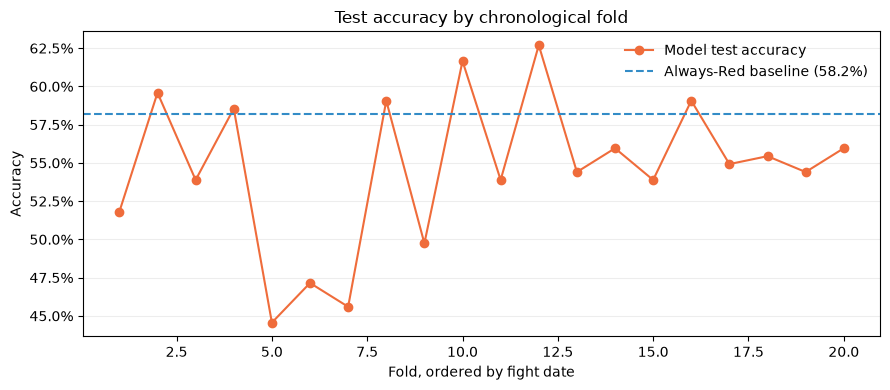

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fold_results["fold"], fold_results["test_accuracy"], marker="o", color="#ef6c3b", label="Model test accuracy")
ax.axhline(0.582, color="#338cc7", linestyle="--", label="Always-Red baseline (58.2%)")
ax.set(title="Test accuracy by chronological fold", xlabel="Fold, ordered by fight date", ylabel="Accuracy")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", alpha=0.22)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Interpretation

Some folds hit the 200-iteration limit, so the saved result is not guaranteed to be fully converged. A high training score with a lower later-period test score would indicate overfitting.

The reference scores are not a like-for-like benchmark because its original sample spans 1997–2019, has 134 features, and includes three outcomes. This dataset starts in 2010 and the selected slice has only Red and Blue outcomes. Treat the paper comparison as approximate.

**Sources:** [McQuaide (2019) report](https://cs229.stanford.edu/proj2019aut/data/assignment_308832_raw/26647731.pdf) · [TidyTuesday dataset documentation](https://github.com/rfordatascience/tidytuesday/tree/main/data/2026/2026-07-07)
